# SEM / Path Analysis
This notebook evaluates the documented observed-variable pathway from operating conditions through new EIS measurements to SOH. It uses Tier A and B rows only when the EIS operation index changes within a battery, so a carried-forward impedance value is not counted as a new measurement. The analysis is associational and accounts for repeated battery rows only in its battery-block bootstrap uncertainty.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from semopy import Model, calc_stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
pd.set_option('display.max_columns',None)
PROJECT_ROOT=Path.cwd().parent
cycles=pd.read_csv(PROJECT_ROOT/'data'/'processed'/'cycles_clean.csv')
print('Cleaned cycle table:',cycles.shape)

Cleaned cycle table: (2658, 40)


## Construct the New-EIS Analysis Dataset
Filter to Tiers A and B, retain rows with observed EIS operation and resistance values, and keep only the first row for each new EIS operation per battery. The operation index, rather than a repeated resistance value, identifies a newly collected measurement. Missingness, row count, battery count, and condition structure are inspected before fitting.

In [2]:
sem_source=cycles[cycles.tier.isin(['A','B'])].copy()
sem_source=sem_source.sort_values(['battery_id','cycle_valid'])
sem_source['new_eis']=sem_source.groupby('battery_id').eis_op_index.transform(lambda x:x.notna() & x.ne(x.shift()))
sem_data=sem_source.loc[sem_source.new_eis].copy()
sem_data=sem_data.dropna(subset=['eis_op_index','Re_ohm','Rct_ohm','soh','ambient_C','I_level_A','discharge_cutoff_V','cycle_valid'])
sem_data['ln_soh']=np.log(sem_data.soh)
print('SEM complete cases:',len(sem_data),'batteries:',sem_data.battery_id.nunique())
display(sem_data[['battery_id','cycle_valid','eis_op_index','Re_ohm','Rct_ohm','soh']].head())
display(sem_data[['ambient_C','I_level_A','discharge_cutoff_V','Re_ohm','Rct_ohm','soh','cycle_valid']].isna().sum().rename('missing').to_frame())
display(sem_data.groupby(['ambient_C','I_level_A','discharge_cutoff_V'],dropna=False).battery_id.nunique().rename('batteries').reset_index())
display(sem_data[['ambient_C','I_level_A','discharge_cutoff_V','cycle_valid','Re_ohm','Rct_ohm','ln_soh']].corr())
assert (sem_data.soh>0).all(), 'SOH must be positive before computing ln(SOH).'

SEM complete cases: 812 batteries: 22


,battery_id,cycle_valid,eis_op_index,Re_ohm,Rct_ohm,soh
19,B0005,20,40.0,0.044669,0.069456,1.000365
20,B0005,21,44.0,0.044843,0.067972,1.000573
21,B0005,22,48.0,0.045101,0.068528,0.994515
22,B0005,23,52.0,0.044172,0.068044,0.988926
23,B0005,24,56.0,0.043787,0.068450,0.988532


,missing
ambient_C,0
I_level_A,0
discharge_cutoff_V,0
Re_ohm,0
Rct_ohm,0
soh,0
cycle_valid,0


,ambient_C,I_level_A,discharge_cutoff_V,batteries
0,4.0,1.0,2.0,1
1,4.0,1.0,2.2,1
2,4.0,1.0,2.5,1
3,4.0,1.0,2.7,1
4,4.0,2.0,2.0,1
5,4.0,2.0,2.5,1
6,4.0,2.0,2.7,1
7,24.0,2.0,2.2,1
8,24.0,2.0,2.5,2
9,24.0,2.0,2.7,3


,ambient_C,I_level_A,discharge_cutoff_V,cycle_valid,Re_ohm,Rct_ohm,ln_soh
ambient_C,1.000000,0.544597,0.000999,0.187484,-0.302574,-0.827911,-0.037107
I_level_A,0.544597,1.000000,-0.390231,-0.009800,0.343463,-0.239280,0.140595
discharge_cutoff_V,0.000999,-0.390231,1.000000,0.051951,-0.067024,-0.082672,-0.039930
cycle_valid,0.187484,-0.009800,0.051951,1.000000,0.122722,-0.155879,-0.649292
Re_ohm,-0.302574,0.343463,-0.067024,0.122722,1.000000,0.609163,-0.052964
Rct_ohm,-0.827911,-0.239280,-0.082672,-0.155879,0.609163,1.000000,-0.008720
ln_soh,-0.037107,0.140595,-0.039930,-0.649292,-0.052964,-0.008720,1.000000


## Define and Estimate the Observed-Variable Path Model
The model includes condition paths to both resistance measures, resistance paths and direct condition paths to log-SOH, and valid cycle as an outcome control. Observed variables avoid unsupported latent measurement constructs. The model fit measures and path estimates are reported where semopy supports them; a failed or unidentified fit is raised rather than replaced with a fabricated result.

In [3]:
model_desc='''
Re_ohm ~ ambient_C + I_level_A + discharge_cutoff_V
Rct_ohm ~ ambient_C + I_level_A + discharge_cutoff_V
ln_soh ~ Re_ohm + Rct_ohm + ambient_C + I_level_A + discharge_cutoff_V + cycle_valid
'''
sem_model=Model(model_desc)
fit_result=sem_model.fit(sem_data)
print(fit_result)
paths=sem_model.inspect(std_est=True)
display(paths)
fit_stats=calc_stats(sem_model)
display(fit_stats.T)
print('Model fit indices are interpreted with the small number of independent batteries and repeated observations in mind.')

Name of objective: MLW
Optimization method: SLSQP
Optimization successful.
Optimization terminated successfully
Objective value: 0.590
Number of iterations: 113
Params: -0.002 0.023 0.025 -0.005 0.017 0.008 0.696 -1.165 -0.005 0.030 0.025 -0.002 0.000 0.000 0.011


,lval,op,rval,Estimate,Est. Std,Std. Err,z-value,p-value
0,Re_ohm,~,ambient_C,-0.002018,-0.779664,0.000078,-25.798611,0.000000e+00
1,Re_ohm,~,I_level_A,0.022595,0.875637,0.000847,26.677124,0.000000e+00
2,Re_ohm,~,discharge_cutoff_V,0.025310,0.275453,0.002530,10.005910,0.000000e+00
3,Rct_ohm,~,ambient_C,-0.005190,-1.005569,0.000112,-46.254706,0.000000e+00
4,Rct_ohm,~,I_level_A,0.016783,0.326178,0.001215,13.814182,0.000000e+00
5,Rct_ohm,~,discharge_cutoff_V,0.008355,0.045600,0.003628,2.302670,2.129739e-02
6,ln_soh,~,Re_ohm,0.695637,0.104493,0.242073,2.873661,4.057445e-03
7,ln_soh,~,Rct_ohm,-1.164744,-0.348859,0.168767,-6.901478,5.146328e-12
8,ln_soh,~,ambient_C,-0.004558,-0.264493,0.001146,-3.978317,6.940469e-05
9,ln_soh,~,I_level_A,0.029574,0.172153,0.008522,3.470213,5.200467e-04


,Value
DoF,13.000000
DoF Baseline,25.000000
chi2,479.289948
chi2 p-value,0.000000
chi2 Baseline,6119.399142
CFI,0.923489
GFI,0.921677
AGFI,0.849379
NFI,0.921677
TLI,0.852863


Model fit indices are interpreted with the small number of independent batteries and repeated observations in mind.


## Direct, Indirect, and Total Path Associations
Report direct paths from conditions to SOH and indirect paths through Re and Rct as products of the fitted path coefficients. Obtain uncertainty and percentile intervals by resampling whole batteries, not individual cycle rows. Bootstrap failures are counted and disclosed. These path products describe statistical mediation patterns and do not establish causal mediation.

In [4]:
def path_est(table,lhs,rhs):
 row=table[(table.lval==lhs)&(table.op=='~')&(table.rval==rhs)]
 if row.empty: raise KeyError(f'Missing path {lhs} ~ {rhs}')
 return float(row['Estimate'].iloc[0])
effect_rows=[]
for predictor in ['ambient_C','I_level_A','discharge_cutoff_V']:
 a_re=path_est(paths,'Re_ohm',predictor); a_rct=path_est(paths,'Rct_ohm',predictor)
 b_re=path_est(paths,'ln_soh','Re_ohm'); b_rct=path_est(paths,'ln_soh','Rct_ohm')
 direct=path_est(paths,'ln_soh',predictor)
 effect_rows.append({'predictor':predictor,'direct':direct,'indirect_via_Re':a_re*b_re,'indirect_via_Rct':a_rct*b_rct,'total_path_association':direct+a_re*b_re+a_rct*b_rct})
effects=pd.DataFrame(effect_rows)
display(effects)
rng=np.random.default_rng(42); battery_ids=sem_data.battery_id.unique(); boot=[]; failures=0
for rep in range(200):
 sampled=rng.choice(battery_ids,size=len(battery_ids),replace=True)
 blocks=[sem_data[sem_data.battery_id==bid] for bid in sampled]
 boot_data=pd.concat(blocks,ignore_index=True)
 try:
  bm=Model(model_desc); bm.fit(boot_data); bp=bm.inspect(std_est=False)
  row={}
  for predictor in ['ambient_C','I_level_A','discharge_cutoff_V']:
   d=path_est(bp,'ln_soh',predictor)
   ir=path_est(bp,'Re_ohm',predictor)*path_est(bp,'ln_soh','Re_ohm')
   it=path_est(bp,'Rct_ohm',predictor)*path_est(bp,'ln_soh','Rct_ohm')
   row[predictor+'_direct']=d; row[predictor+'_indirect']=ir+it; row[predictor+'_total']=d+ir+it
  boot.append(row)
 except Exception:
  failures+=1
boot_df=pd.DataFrame(boot)
print('Successful battery-block bootstrap replicates:',len(boot_df),'failed:',failures)
if len(boot_df):
 intervals=[]
 for predictor in ['ambient_C','I_level_A','discharge_cutoff_V']:
  for kind in ['direct','indirect','total']:
   col=predictor+'_'+kind
   intervals.append({'predictor':predictor,'effect':kind,'bootstrap_SE':boot_df[col].std(ddof=1),'CI_2.5':boot_df[col].quantile(.025),'CI_97.5':boot_df[col].quantile(.975)})
 display(pd.DataFrame(intervals))

,predictor,direct,indirect_via_Re,indirect_via_Rct,total_path_association
0,ambient_C,-0.004558,-0.001404,0.006045,0.000083
1,I_level_A,0.029574,0.015718,-0.019548,0.025744
2,discharge_cutoff_V,0.024741,0.017607,-0.009731,0.032616


Successful battery-block bootstrap replicates: 200 failed: 0


,predictor,effect,bootstrap_SE,CI_2.5,CI_97.5
0,ambient_C,direct,0.017845,-0.044090,0.021549
1,ambient_C,indirect,0.029668,-0.012248,0.041062
2,ambient_C,total,0.033431,-0.062100,0.064665
3,I_level_A,direct,0.205894,-0.119877,0.171961
4,I_level_A,indirect,0.236458,-0.152590,0.126263
5,I_level_A,total,0.333270,-0.286252,0.301366
6,discharge_cutoff_V,direct,0.408308,-0.189997,0.551041
7,discharge_cutoff_V,indirect,0.103008,-0.172327,0.190621
8,discharge_cutoff_V,total,0.433025,-0.236460,0.592977


## Path Diagram and Limitations
Draw the hypothesized observed-variable graph for the report. Interpret coefficients as conditional associations on log-SOH. Incomplete condition crossing, limited independent batteries, within-battery dependence, and observational path assumptions limit claims about independent effects and mediation.

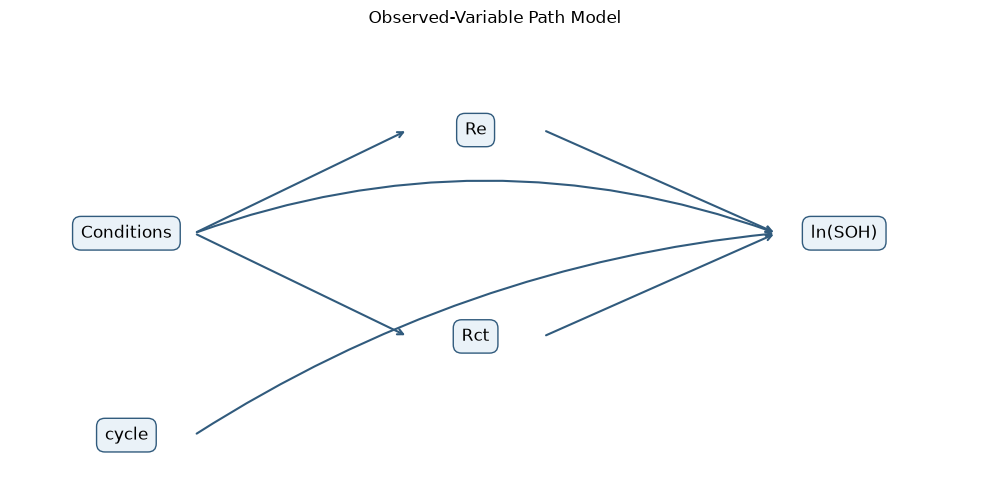

Interpretation is associational. New-EIS filtering avoids counting carried-forward EIS values as fresh measurements, but repeated measurements within each battery remain dependent.


In [5]:
fig,ax=plt.subplots(figsize=(10,5)); ax.axis('off')
pos={'Conditions':(.12,.55),'Re':(.48,.78),'Rct':(.48,.32),'ln(SOH)':(.86,.55),'cycle':(.12,.1)}
for label,(x,y) in pos.items():
 ax.text(x,y,label,ha='center',va='center',bbox=dict(boxstyle='round,pad=.5',fc='#eaf2f8',ec='#315b7d'),fontsize=12)
def arrow(a,b,curve=0):
 x1,y1=pos[a]; x2,y2=pos[b]
 ax.annotate('',xy=(x2-.07,y2),xytext=(x1+.07,y1),arrowprops=dict(arrowstyle='->',lw=1.5,color='#315b7d',connectionstyle=f'arc3,rad={curve}'))
arrow('Conditions','Re'); arrow('Conditions','Rct'); arrow('Re','ln(SOH)'); arrow('Rct','ln(SOH)'); arrow('Conditions','ln(SOH)',-.18); arrow('cycle','ln(SOH)',-.12)
ax.set_title('Observed-Variable Path Model')
fig.tight_layout(); fig.savefig(PROJECT_ROOT/'reports'/'figures'/'sem_path_diagram.png',dpi=160,bbox_inches='tight'); plt.show()
print('Interpretation is associational. New-EIS filtering avoids counting carried-forward EIS values as fresh measurements, but repeated measurements within each battery remain dependent.')

## Key Findings
The executed output tables above provide sample size, missingness, fit indices, path coefficients, indirect and total path associations, and battery-block bootstrap intervals. Summarize only those observed results after the notebook runs successfully.

In [6]:
print('New EIS measurements:',len(sem_data),'from',sem_data.battery_id.nunique(),'Tier A/B batteries.')
print('Review fit indices, direct and indirect path tables, and bootstrap interval coverage before making any substantive conclusion.')
print('The analysis is observational, conditions are partially confounded, and repeated EIS measurements are nested within batteries.')

New EIS measurements: 812 from 22 Tier A/B batteries.
Review fit indices, direct and indirect path tables, and bootstrap interval coverage before making any substantive conclusion.
The analysis is observational, conditions are partially confounded, and repeated EIS measurements are nested within batteries.
